# Bandeira Viva · Machine Learning
## Prever se a próxima coleta de água de uma praia da Baixada Santista vai passar do limite de enterococos

**Global Solution 2026.2 · Inteligência Artificial & Machine Learning · FIAP Engenharia de Software**

Equipe: Luiz Felipe Motta da Silva (RM 559126) · Nicolas Lorenzo Ferreira da Silva (RM 557962) · Pedro Henrique Faim dos Santos (RM 557440)

### O problema da CitizenTech
O Bandeira Viva quer avisar moradores e trabalhadores da praia de São Vicente, antes de saírem de casa, se a água tende a estar segura. Hoje a informação oficial é o boletim semanal da CETESB, que classifica cada ponto olhando as **últimas cinco coletas**. Quando a água piora de repente, a bandeira demora a mudar.

### A pergunta de Machine Learning
> **Com base nas coletas recentes do próprio ponto e da região e na época do ano, a próxima coleta semanal do ponto vai passar de 100 UFC/100 mL de enterococos?**

- **Tipo:** classificação binária supervisionada.
- **Alvo:** `1` se a coleta da semana seguinte tiver mais de 100 UFC/100 mL, valor acima do qual a amostra é considerada ruim pelo critério da CONAMA 274/2000 usado pela CETESB.
- **Quem usa a resposta:** o app mostra um alerta de **risco de água ruim na próxima semana** por ponto de praia.

### Dados reais e públicos
Resultados semanais de enterococos publicados pela **CETESB** nos boletins de balneabilidade, entre jan/2012 e jul/2021. Fonte, link, período e tratamento estão documentados em `dados/README.md`.

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dateutil.easter import easter
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
np.random.seed(SEED)
BASE = Path.cwd() if (Path.cwd() / "dados").exists() else Path.cwd() / "ml"
DADOS, FIG, RES = BASE / "dados", BASE / "figuras", BASE / "resultados"
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True); (DADOS / "processados").mkdir(exist_ok=True)

COR = {"teal": "#0a7f8c", "coral": "#d63031", "ambar": "#e0a100", "cinza": "#8a9aa8", "azul": "#1f6fc4"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
LIMITE = 100  # UFC/100 mL
print("Pasta do projeto:", BASE)

Pasta do projeto: /home/claude/work/bandeira-viva-ml/ml


## 1. Problema e dados reais
### 1.1 Carregar os resultados da CETESB
O arquivo bruto tem uma linha por coleta: município, ponto de praia, data e densidade de enterococos (UFC/100 mL). Usamos os quatro municípios centrais da Baixada Santista: **São Vicente** (foco do Bandeira Viva), Santos, Praia Grande e Guarujá. Eles compartilham o mesmo estuário e o mesmo regime de chuva, o que dá ao modelo mais exemplos de como a contaminação se espalha pela região.

In [2]:
bruto = pd.read_csv(DADOS / "brutos" / "cetesb_enterococos_sp_2012_2021.csv", parse_dates=["Date"])
print(f"Arquivo bruto: {len(bruto):,} coletas · {bruto.City.nunique()} municípios · {bruto.groupby(['City','Beach']).ngroups} pontos")
print("Período:", bruto.Date.min().date(), "a", bruto.Date.max().date())

MUNICIPIOS = ["SÃO VICENTE", "SANTOS", "PRAIA GRANDE", "GUARUJÁ"]
df = bruto[bruto.City.isin(MUNICIPIOS)].rename(columns={"City": "municipio", "Beach": "praia", "Date": "data", "Enterococcus": "enterococos"}).copy()
df["ponto"] = df.municipio + " | " + df.praia
print(f"Baixada Santista central: {len(df):,} coletas em {df.ponto.nunique()} pontos")
df.head()

Arquivo bruto: 74,056 coletas · 16 municípios · 176 pontos
Período: 2012-01-03 a 2021-07-19
Baixada Santista central: 16,528 coletas em 37 pontos


,municipio,praia,data,enterococos,ponto
1247,GUARUJÁ,PEREQUÊ,2012-01-03,560.0,GUARUJÁ | PEREQUÊ
1248,GUARUJÁ,PEREQUÊ,2012-01-08,440.0,GUARUJÁ | PEREQUÊ
1249,GUARUJÁ,PEREQUÊ,2012-01-15,228.0,GUARUJÁ | PEREQUÊ
1250,GUARUJÁ,PEREQUÊ,2012-01-22,320.0,GUARUJÁ | PEREQUÊ
1251,GUARUJÁ,PEREQUÊ,2012-01-29,104.0,GUARUJÁ | PEREQUÊ


### 1.2 Limpeza
- **Nomes repetidos:** "Praia da Divisa" existe em São Vicente e em Praia Grande, por isso o ponto é identificado por município + praia.
- **Semana de coleta:** a CETESB coleta aos domingos, mas algumas datas foram registradas na segunda-feira seguinte. Cada coleta é atribuída à semana que termina no domingo, e fica no máximo uma coleta por ponto por semana.
- **Faltantes e duplicatas:** verificamos valores ausentes, negativos e repetidos.
- **Escala:** a densidade varia de 1 a 5.000 UFC, com cauda muito longa, então os atributos usam `log(1 + enterococos)`.

In [3]:
print("Valores ausentes:", int(df.enterococos.isna().sum()), "| valores <= 0:", int((df.enterococos <= 0).sum()))
df["semana"] = (df.data - pd.Timedelta(days=1)).dt.to_period("W-SUN")
antes = len(df)
df = df.sort_values(["ponto", "data"]).drop_duplicates(["ponto", "semana"], keep="last").reset_index(drop=True)
print("Coletas duplicadas na mesma semana removidas:", antes - len(df))
df["log_ent"] = np.log1p(df.enterococos)
df["acima"] = (df.enterococos > LIMITE).astype(int)
print(f"Coletas acima de {LIMITE} UFC/100 mL: {df.acima.mean():.1%} na região · {df[df.municipio=='SÃO VICENTE'].acima.mean():.1%} em São Vicente")
df.groupby(df.data.dt.year).size().rename("coletas por ano").to_frame().T

Valores ausentes: 0 | valores <= 0: 0
Coletas duplicadas na mesma semana removidas: 36
Coletas acima de 100 UFC/100 mL: 23.8% na região · 36.0% em São Vicente


data,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
coletas por ano,1872,1620,1776,1884,1884,1920,1884,1884,898,870


### 1.3 Análise exploratória
Duas perguntas guiam os atributos: **há época do ano mais arriscada?** e **São Vicente é diferente dos vizinhos?**

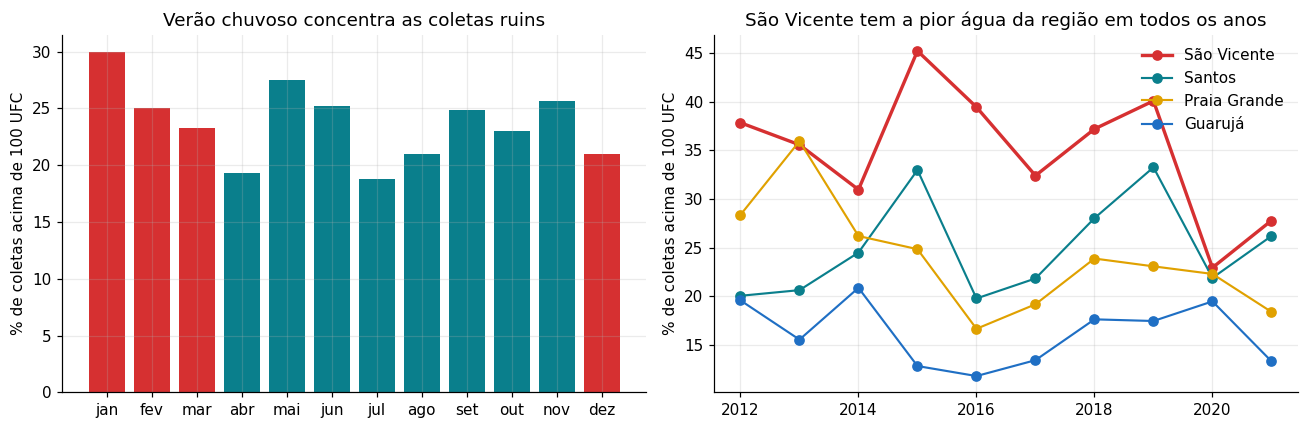

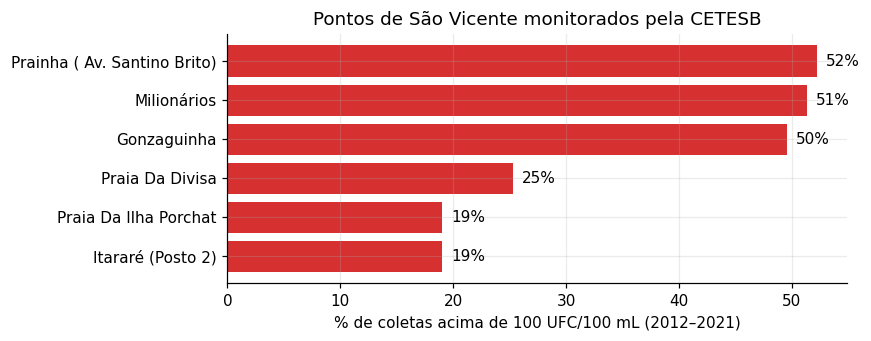

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
mes = df.groupby(df.data.dt.month).acima.mean() * 100
ax[0].bar(mes.index, mes.values, color=[COR["coral"] if m in (12, 1, 2, 3) else COR["teal"] for m in mes.index])
ax[0].set_xticks(range(1, 13), ["jan","fev","mar","abr","mai","jun","jul","ago","set","out","nov","dez"])
ax[0].set_ylabel("% de coletas acima de 100 UFC"); ax[0].set_title("Verão chuvoso concentra as coletas ruins")
ano = df.groupby([df.data.dt.year, "municipio"]).acima.mean().unstack() * 100
for c, cor in zip(MUNICIPIOS, [COR["coral"], COR["teal"], COR["ambar"], COR["azul"]]):
    ax[1].plot(ano.index, ano[c], marker="o", label=c.title(), color=cor, lw=2.2 if c == "SÃO VICENTE" else 1.4)
ax[1].set_ylabel("% de coletas acima de 100 UFC"); ax[1].set_title("São Vicente tem a pior água da região em todos os anos"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig01_sazonalidade_e_municipios.png", bbox_inches="tight"); plt.show()

sv = df[df.municipio == "SÃO VICENTE"].groupby("praia").acima.mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(sv.index.str.title(), sv.values, color=COR["coral"])
for i, v in enumerate(sv.values): ax.text(v + 0.8, i, f"{v:.0f}%", va="center")
ax.set_xlabel("% de coletas acima de 100 UFC/100 mL (2012–2021)"); ax.set_title("Pontos de São Vicente monitorados pela CETESB")
plt.tight_layout(); plt.savefig(FIG / "fig02_sao_vicente_pontos.png", bbox_inches="tight"); plt.show()

## 2. Preparação dos atributos (sem olhar o futuro)
Cada linha representa **um ponto numa semana `t`**, e o alvo é a coleta da **semana `t+1`**. Todos os atributos usam apenas informação publicada até a semana `t`, o que evita vazamento de dados.

| Grupo | Atributos | Por quê |
|---|---|---|
| Histórico do ponto | `log_lag0..3` (últimas 4 coletas), `media5`, `max5`, `acima5` (quantas das últimas 5 passaram de 100) | A contaminação persiste; `acima5` reproduz a lógica do boletim da CETESB |
| Perfil do ponto | `hist_ponto`: proporção de coletas ruins do ponto **até a semana t** | Pontos perto de galerias pluviais pioram mais |
| Região na mesma semana | `reg_med`, `reg_frac`, `cid_frac`, `reg_med_lag1` | Uma piora simultânea em vários pontos indica chuva forte e esgoto chegando ao mar. É a nossa forma de captar o efeito da chuva só com dados da CETESB |
| Calendário da semana-alvo | `mes_sin`, `mes_cos`, `temporada` (dez–fev), `carnaval` | Verão chuvoso e população flutuante |
| Município | variáveis indicadoras | Diferenças estruturais de saneamento |

Mantemos só os pares com intervalo de 4 a 10 dias entre as coletas, ou seja, a **próxima semana** de fato.

In [5]:
df = df.sort_values(["ponto", "data"]).reset_index(drop=True)
g = df.groupby("ponto")
for k in range(4):
    df[f"log_lag{k}"] = g.log_ent.shift(k)
df["media5"] = g.log_ent.transform(lambda s: s.rolling(5, min_periods=3).mean())
df["max5"] = g.log_ent.transform(lambda s: s.rolling(5, min_periods=3).max())
df["acima5"] = g.acima.transform(lambda s: s.rolling(5, min_periods=3).sum())
df["hist_ponto"] = g.acima.transform(lambda s: s.expanding().mean())

regiao = df.groupby("semana").agg(reg_med=("log_ent", "median"), reg_frac=("acima", "mean"))
cidade = df.groupby(["semana", "municipio"]).agg(cid_frac=("acima", "mean")).reset_index()
df = df.merge(regiao, on="semana", how="left").merge(cidade, on=["semana", "municipio"], how="left")
df = df.sort_values(["ponto", "data"]).reset_index(drop=True)
g = df.groupby("ponto")
df["reg_med_lag1"] = g.reg_med.shift(1)

df["data_alvo"] = g.data.shift(-1)
df["alvo"] = g.acima.shift(-1)
df["ent_alvo"] = g.enterococos.shift(-1)
df["intervalo_dias"] = (df.data_alvo - df.data).dt.days

def semana_de_carnaval(d):
    terca = pd.Timestamp(easter(d.year)) - pd.Timedelta(days=47)
    return int(abs((d - terca).days) <= 4)

mes_alvo = df.data_alvo.dt.month
df["mes_sin"], df["mes_cos"] = np.sin(2 * np.pi * mes_alvo / 12), np.cos(2 * np.pi * mes_alvo / 12)
df["temporada"] = mes_alvo.isin([12, 1, 2]).astype(float)
df["carnaval"] = df.data_alvo.apply(lambda d: semana_de_carnaval(d) if pd.notna(d) else np.nan)

base = df[df.intervalo_dias.between(4, 10)].dropna(subset=["log_lag3", "media5", "reg_med_lag1", "alvo"]).copy()
base["alvo"] = base.alvo.astype(int)
base = pd.concat([base, pd.get_dummies(base.municipio, prefix="mun", dtype=int)], axis=1)

ATRIBUTOS = ["log_lag0", "log_lag1", "log_lag2", "log_lag3", "media5", "max5", "acima5", "hist_ponto",
             "reg_med", "reg_frac", "cid_frac", "reg_med_lag1", "mes_sin", "mes_cos", "temporada", "carnaval"] + \
            [c for c in base.columns if c.startswith("mun_")]
print(f"Base de modelagem: {len(base):,} exemplos · {len(ATRIBUTOS)} atributos · {base.alvo.mean():.1%} positivos")
base[["ponto", "data", "data_alvo", "enterococos", "ent_alvo", "alvo"] + ATRIBUTOS[:6]].head()

Base de modelagem: 16,043 exemplos · 20 atributos · 23.6% positivos


,ponto,data,data_alvo,enterococos,ent_alvo,alvo,log_lag0,log_lag1,log_lag2,log_lag3,media5,max5
3,GUARUJÁ | ASTÚRIAS,2012-01-29,2012-02-05,96.0,6.0,0,4.574711,3.931826,1.791759,2.772589,3.267721,4.574711
4,GUARUJÁ | ASTÚRIAS,2012-02-05,2012-02-12,6.0,268.0,1,1.945910,4.574711,3.931826,1.791759,3.003359,4.574711
5,GUARUJÁ | ASTÚRIAS,2012-02-12,2012-02-19,268.0,120.0,1,5.594711,1.945910,4.574711,3.931826,3.567784,5.594711
6,GUARUJÁ | ASTÚRIAS,2012-02-19,2012-02-26,120.0,25.0,0,4.795791,5.594711,1.945910,4.574711,4.168590,5.594711
7,GUARUJÁ | ASTÚRIAS,2012-02-26,2012-03-04,25.0,3.0,0,3.258097,4.795791,5.594711,1.945910,4.033844,5.594711


### 2.1 Divisão treino/teste temporal
Num problema de previsão, não se pode embaralhar as semanas: o modelo precisa ser testado em um **período futuro que nunca viu**.
- **Treino:** semanas-alvo de 2012 a 2017.
- **Teste:** semanas-alvo de 2018 a jul/2021. Inclui 2020, quando a pandemia reduziu as coletas, o que torna o teste um retrato realista de mudança de cenário.

A validação cruzada (seção 4) usa **somente o treino**, em blocos de semanas consecutivas (`TimeSeriesSplit`).

In [6]:
CORTE = pd.Timestamp("2018-01-01")
treino = base[base.data_alvo < CORTE].sort_values("data_alvo").reset_index(drop=True)
teste = base[base.data_alvo >= CORTE].sort_values("data_alvo").reset_index(drop=True)
X_tr, y_tr, X_te, y_te = treino[ATRIBUTOS], treino.alvo, teste[ATRIBUTOS], teste.alvo
resumo_split = pd.DataFrame({
    "período": [f"{treino.data_alvo.min():%m/%Y} a {treino.data_alvo.max():%m/%Y}", f"{teste.data_alvo.min():%m/%Y} a {teste.data_alvo.max():%m/%Y}"],
    "exemplos": [len(treino), len(teste)], "% positivos": [f"{y_tr.mean():.1%}", f"{y_te.mean():.1%}"]}, index=["treino", "teste"])
base.to_csv(DADOS / "processados" / "base_modelagem.csv", index=False)
resumo_split

,período,exemplos,% positivos
treino,02/2012 a 12/2017,10692,23.5%
teste,01/2018 a 07/2021,5351,23.9%


### 2.2 Referências simples (baselines)
Um modelo só vale a pena se superar regras óbvias:
1. **Persistência:** a próxima coleta repete a situação da atual.
2. **Regra da CETESB:** o ponto é considerado de risco se 2 das últimas 5 coletas passaram de 100 ou se a última passou de 400 (critério do boletim).

In [7]:
def metricas(y, pred, prob=None):
    m = {"acurácia": accuracy_score(y, pred), "acurácia balanceada": balanced_accuracy_score(y, pred),
         "precisão": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred), "F1": f1_score(y, pred)}
    if prob is not None:
        m["ROC-AUC"], m["PR-AUC"] = roc_auc_score(y, prob), average_precision_score(y, prob)
    return m

baselines = {
    "Persistência": (teste.log_lag0 > np.log1p(LIMITE)).astype(int),
    "Regra CETESB (2 de 5 ou >400)": ((teste.acima5 >= 2) | (teste.log_lag0 > np.log1p(400))).astype(int),
}
tab_base = pd.DataFrame({k: metricas(y_te, v) for k, v in baselines.items()}).T
tab_base.round(3)

,acurácia,acurácia balanceada,precisão,recall,F1
Persistência,0.662,0.541,0.299,0.310,0.304
Regra CETESB (2 de 5 ou >400),0.611,0.558,0.297,0.457,0.360


## 3. Escolha do modelo
Comparamos dois modelos de árvores da lista da disciplina:

| Modelo | Por que serve para este problema |
|---|---|
| **Random Forest** | Dados tabulares com relações não lineares (o efeito da chuva só aparece acima de certo nível). É robusto a ruído, comum em contagem de bactérias, e pouco sensível à escala. Com `class_weight="balanced"`, lida com a minoria de semanas ruins (24%) |
| **XGBoost** | Boosting costuma ter a melhor acurácia em dados tabulares e captura interações finas (região × temporada). É mais propenso a overfitting, o que exige controle de profundidade e taxa de aprendizado |

Ficaram de fora: **MLP**, porque cerca de 10 mil linhas tabulares não justificam uma rede neural e a interpretação ficaria pior; **LSTM**, porque as séries por ponto são curtas, com cerca de 460 semanas e falhas em 2020; **KMeans + PCA**, porque é não supervisionado e não responde a uma pergunta com rótulo. A escolha final entre RF e XGBoost é feita pela **validação cruzada no treino**, nunca pelo teste.

## 4. Treino com diferentes hiperparâmetros
- **Random Forest:** 3 hiperparâmetros, `n_estimators` × `max_depth` × `min_samples_leaf`, em **18 combinações**.
- **XGBoost:** 3 hiperparâmetros, `max_depth` × `learning_rate` × `n_estimators`, em **12 combinações**.
- **Validação cruzada:** 5 dobras temporais **só no treino**. As dobras são cortadas por semana, para que pontos da mesma semana não fiquem divididos entre treino e validação.
- **Métrica de seleção:** PR-AUC (*average precision*), adequada para classe minoritária. Também registramos ROC-AUC e o desempenho no próprio treino, para medir overfitting.

In [8]:
class SemanasTimeSeriesSplit:
    # TimeSeriesSplit aplicado às semanas: cada dobra valida em semanas posteriores às de treino
    def __init__(self, semanas, n_splits=5):
        self.semanas, self.n_splits = np.asarray(semanas), n_splits
    def split(self, X=None, y=None, groups=None):
        unicas = np.unique(self.semanas)
        for i_tr, i_va in TimeSeriesSplit(self.n_splits).split(unicas):
            yield np.where(np.isin(self.semanas, unicas[i_tr]))[0], np.where(np.isin(self.semanas, unicas[i_va]))[0]
    def get_n_splits(self, *a, **k):
        return self.n_splits

cv = SemanasTimeSeriesSplit(treino.data_alvo.values, n_splits=5)
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

grid_rf = GridSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1),
    {"n_estimators": [200, 500], "max_depth": [4, 8, 16], "min_samples_leaf": [1, 10, 40]},
    scoring=SCORING, refit="pr_auc", cv=cv, return_train_score=True, n_jobs=1).fit(X_tr, y_tr)

razao = (y_tr == 0).sum() / (y_tr == 1).sum()
grid_xgb = GridSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, scale_pos_weight=razao, eval_metric="logloss", random_state=SEED, n_jobs=-1),
    {"max_depth": [2, 4, 6], "learning_rate": [0.03, 0.1], "n_estimators": [150, 400]},
    scoring=SCORING, refit="pr_auc", cv=cv, return_train_score=True, n_jobs=1).fit(X_tr, y_tr)

def tabela_grid(grid, nome):
    r = pd.DataFrame(grid.cv_results_)
    cols = [c for c in r.columns if c.startswith("param_")]
    t = r[cols + ["mean_train_pr_auc", "mean_test_pr_auc", "std_test_pr_auc", "mean_train_roc_auc", "mean_test_roc_auc"]].copy()
    t.columns = [c.replace("param_", "") for c in cols] + ["PR-AUC treino", "PR-AUC validação", "desvio validação", "ROC-AUC treino", "ROC-AUC validação"]
    t["gap PR-AUC (treino − validação)"] = t["PR-AUC treino"] - t["PR-AUC validação"]
    t.insert(0, "modelo", nome)
    return t.sort_values("PR-AUC validação", ascending=False).reset_index(drop=True)

res_rf, res_xgb = tabela_grid(grid_rf, "Random Forest"), tabela_grid(grid_xgb, "XGBoost")
res_rf.to_csv(RES / "grid_random_forest.csv", index=False); res_xgb.to_csv(RES / "grid_xgboost.csv", index=False)
print(f"Combinações testadas: RF = {len(res_rf)} · XGBoost = {len(res_xgb)}")
res_rf.round(3)

Combinações testadas: RF = 18 · XGBoost = 12


,modelo,max_depth,min_samples_leaf,n_estimators,PR-AUC treino,PR-AUC validação,desvio validação,ROC-AUC treino,ROC-AUC validação,gap PR-AUC (treino − validação)
0,Random Forest,4,10,200,0.566,0.407,0.025,0.779,0.672,0.159
1,Random Forest,4,40,200,0.543,0.407,0.026,0.772,0.670,0.136
2,Random Forest,4,10,500,0.567,0.406,0.027,0.781,0.670,0.161
3,Random Forest,4,40,500,0.544,0.405,0.026,0.772,0.669,0.139
4,Random Forest,4,1,200,0.574,0.405,0.026,0.782,0.671,0.169
5,Random Forest,4,1,500,0.576,0.404,0.027,0.783,0.669,0.171
6,Random Forest,8,1,200,0.850,0.402,0.036,0.937,0.667,0.448
7,Random Forest,8,10,200,0.778,0.400,0.031,0.905,0.669,0.377
8,Random Forest,8,10,500,0.780,0.400,0.032,0.906,0.667,0.380
9,Random Forest,16,10,200,0.893,0.399,0.038,0.958,0.661,0.494


In [9]:
res_xgb.round(3)

,modelo,learning_rate,max_depth,n_estimators,PR-AUC treino,PR-AUC validação,desvio validação,ROC-AUC treino,ROC-AUC validação,gap PR-AUC (treino − validação)
0,XGBoost,0.03,2,150,0.593,0.382,0.030,0.799,0.651,0.211
1,XGBoost,0.03,4,150,0.780,0.380,0.040,0.900,0.646,0.401
2,XGBoost,0.03,6,150,0.914,0.375,0.038,0.964,0.648,0.539
3,XGBoost,0.03,2,400,0.688,0.364,0.036,0.854,0.628,0.324
4,XGBoost,0.03,4,400,0.890,0.361,0.043,0.951,0.634,0.530
5,XGBoost,0.10,6,150,0.988,0.360,0.047,0.995,0.634,0.628
6,XGBoost,0.03,6,400,0.980,0.358,0.036,0.992,0.639,0.622
7,XGBoost,0.10,2,150,0.713,0.357,0.037,0.866,0.627,0.356
8,XGBoost,0.10,6,400,1.000,0.351,0.041,1.000,0.629,0.649
9,XGBoost,0.10,4,150,0.908,0.345,0.040,0.961,0.622,0.563


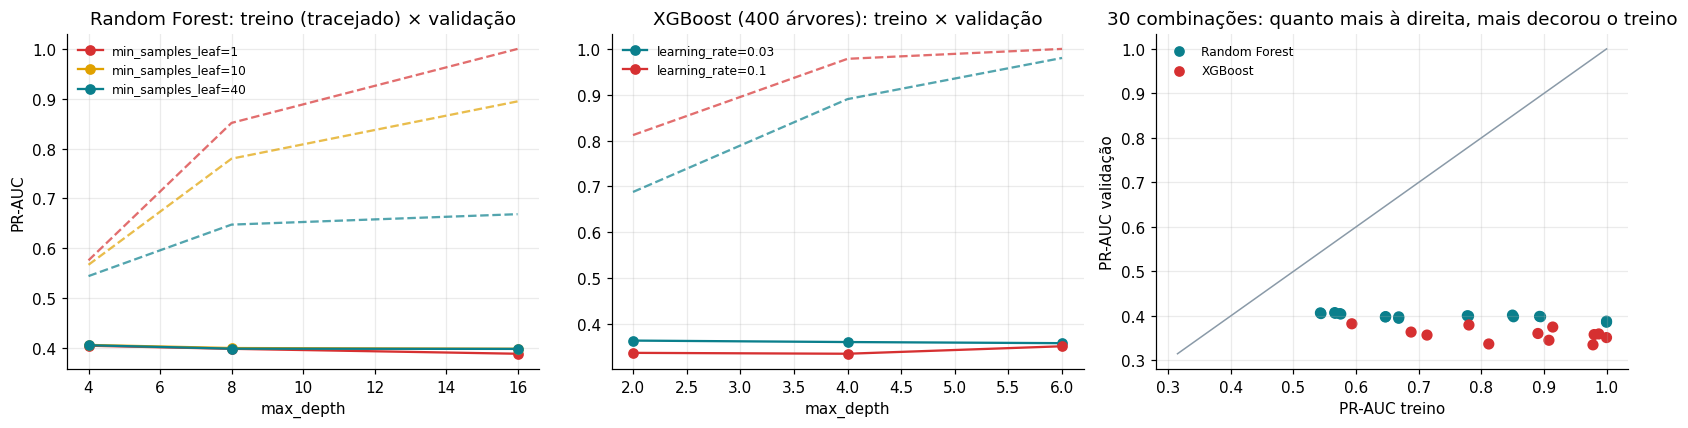

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
r = pd.DataFrame(grid_rf.cv_results_)
for leaf, cor in zip([1, 10, 40], [COR["coral"], COR["ambar"], COR["teal"]]):
    s = r[(r.param_min_samples_leaf == leaf) & (r.param_n_estimators == 500)].sort_values("param_max_depth")
    ax[0].plot(s.param_max_depth.astype(int), s.mean_train_pr_auc, "--", color=cor, alpha=0.7)
    ax[0].plot(s.param_max_depth.astype(int), s.mean_test_pr_auc, "o-", color=cor, label=f"min_samples_leaf={leaf}")
ax[0].set_xlabel("max_depth"); ax[0].set_ylabel("PR-AUC"); ax[0].set_title("Random Forest: treino (tracejado) × validação"); ax[0].legend(frameon=False, fontsize=8)

x = pd.DataFrame(grid_xgb.cv_results_)
for lr, cor in zip([0.03, 0.1], [COR["teal"], COR["coral"]]):
    s = x[(x.param_learning_rate == lr) & (x.param_n_estimators == 400)].sort_values("param_max_depth")
    ax[1].plot(s.param_max_depth.astype(int), s.mean_train_pr_auc, "--", color=cor, alpha=0.7)
    ax[1].plot(s.param_max_depth.astype(int), s.mean_test_pr_auc, "o-", color=cor, label=f"learning_rate={lr}")
ax[1].set_xlabel("max_depth"); ax[1].set_title("XGBoost (400 árvores): treino × validação"); ax[1].legend(frameon=False, fontsize=8)

todas = pd.concat([res_rf, res_xgb])
ax[2].scatter(todas["PR-AUC treino"], todas["PR-AUC validação"], c=[COR["teal"] if m == "Random Forest" else COR["coral"] for m in todas.modelo], s=40)
lim = [todas[["PR-AUC treino", "PR-AUC validação"]].min().min() - 0.02, 1.0]
ax[2].plot(lim, lim, color=COR["cinza"], lw=1); ax[2].set_xlabel("PR-AUC treino"); ax[2].set_ylabel("PR-AUC validação")
ax[2].set_title("30 combinações: quanto mais à direita, mais decorou o treino")
ax[2].scatter([], [], c=COR["teal"], label="Random Forest"); ax[2].scatter([], [], c=COR["coral"], label="XGBoost"); ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig03_hiperparametros_treino_vs_validacao.png", bbox_inches="tight"); plt.show()

### 4.1 Modelo escolhido e limiar de alerta
Escolhemos o modelo com a **maior PR-AUC média na validação cruzada**. O limiar de decisão também sai só do treino: usamos as previsões fora da dobra (*out-of-fold*) para encontrar, **em cada município**, o maior limiar que ainda alcança **recall de 75%**, a meta do indicador de impacto da ficha.

O limiar é calibrado por município porque a frequência de água ruim é muito diferente entre eles: 36% das coletas em São Vicente contra 16% em Guarujá. Um limiar único faria o app alertar quase toda semana em São Vicente. Para o cidadão, deixar passar uma semana ruim é pior do que um alerta a mais, mas alertar sempre também tira a utilidade do aviso.

In [11]:
melhor_nome = "Random Forest" if grid_rf.best_score_ >= grid_xgb.best_score_ else "XGBoost"
melhor_grid = grid_rf if melhor_nome == "Random Forest" else grid_xgb
print(f"Melhor RF  (validação PR-AUC {grid_rf.best_score_:.3f}):", grid_rf.best_params_)
print(f"Melhor XGB (validação PR-AUC {grid_xgb.best_score_:.3f}):", grid_xgb.best_params_)
print("→ Modelo escolhido:", melhor_nome)

oof_prob, oof_y, oof_idx = [], [], []
for i_tr, i_va in cv.split():
    m = clone(melhor_grid.best_estimator_).fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
    oof_prob.append(m.predict_proba(X_tr.iloc[i_va])[:, 1]); oof_y.append(y_tr.iloc[i_va].values); oof_idx.append(i_va)
oof_prob, oof_y, oof_idx = np.concatenate(oof_prob), np.concatenate(oof_y), np.concatenate(oof_idx)
oof_mun = treino.municipio.values[oof_idx]

META_RECALL = 0.75
def limiar_para_recall(y, prob, meta=META_RECALL):
    prec, rec, lim = precision_recall_curve(y, prob)
    ok = np.where(rec[:-1] >= meta)[0]
    return float(lim[ok[-1]])

LIMIARES = {mun: limiar_para_recall(oof_y[oof_mun == mun], oof_prob[oof_mun == mun]) for mun in MUNICIPIOS}
def alerta(prob, municipios):
    return (np.asarray(prob) >= np.array([LIMIARES[m] for m in municipios])).astype(int)

print("Limiar de alerta por município (calibrado no treino, recall-alvo 75%):")
for mun, l in LIMIARES.items():
    sel = oof_mun == mun
    print(f"  {mun:13s} limiar {l:.3f} · recall OOF {recall_score(oof_y[sel], (oof_prob[sel] >= l).astype(int)):.2f} · precisão OOF {precision_score(oof_y[sel], (oof_prob[sel] >= l).astype(int)):.2f}")
modelo = melhor_grid.best_estimator_  # já re-treinado em todo o treino pelo GridSearchCV

Melhor RF  (validação PR-AUC 0.407): {'max_depth': 4, 'min_samples_leaf': 10, 'n_estimators': 200}
Melhor XGB (validação PR-AUC 0.382): {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 150}
→ Modelo escolhido: Random Forest


Limiar de alerta por município (calibrado no treino, recall-alvo 75%):
  SÃO VICENTE   limiar 0.502 · recall OOF 0.75 · precisão OOF 0.50
  SANTOS        limiar 0.394 · recall OOF 0.75 · precisão OOF 0.23
  PRAIA GRANDE  limiar 0.403 · recall OOF 0.75 · precisão OOF 0.24
  GUARUJÁ       limiar 0.329 · recall OOF 0.75 · precisão OOF 0.21


## 5. Resultados em treino e teste
### 5.1 Métricas lado a lado
- **Treino:** desempenho nos dados que o modelo já viu, o que mede quanto ele "decorou".
- **Validação (OOF):** estimativa honesta dentro do período de treino.
- **Teste:** o período 2018–2021, nunca visto.

In [12]:
p_tr, p_te = modelo.predict_proba(X_tr)[:, 1], modelo.predict_proba(X_te)[:, 1]
tab = pd.DataFrame({
    "Treino": metricas(y_tr, alerta(p_tr, treino.municipio), p_tr),
    "Validação (OOF)": metricas(oof_y, alerta(oof_prob, oof_mun), oof_prob),
    "Teste 2018–2021": metricas(y_te, alerta(p_te, teste.municipio), p_te),
}).T
outro_grid = grid_xgb if melhor_nome == "Random Forest" else grid_rf
p_out = outro_grid.best_estimator_.predict_proba(X_te)[:, 1]
comp = pd.concat([
    pd.DataFrame({f"{melhor_nome} (escolhido)": metricas(y_te, alerta(p_te, teste.municipio), p_te)}).T,
    pd.DataFrame({("XGBoost" if melhor_nome == "Random Forest" else "Random Forest") + " (melhor da busca, mesmos limiares)": metricas(y_te, alerta(p_out, teste.municipio), p_out)}).T,
    tab_base])
display(tab.round(3)); print("Comparação no TESTE:"); display(comp.round(3))

,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC,PR-AUC
Treino,0.473,0.617,0.294,0.888,0.442,0.741,0.490
Validação (OOF),0.484,0.578,0.271,0.751,0.398,0.675,0.409
Teste 2018–2021,0.452,0.582,0.281,0.832,0.421,0.668,0.415


Comparação no TESTE:


,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC,PR-AUC
Random Forest (escolhido),0.452,0.582,0.281,0.832,0.421,0.668,0.415
"XGBoost (melhor da busca, mesmos limiares)",0.514,0.607,0.301,0.786,0.436,0.676,0.409
Persistência,0.662,0.541,0.299,0.310,0.304,NaN,NaN
Regra CETESB (2 de 5 ou >400),0.611,0.558,0.297,0.457,0.360,NaN,NaN


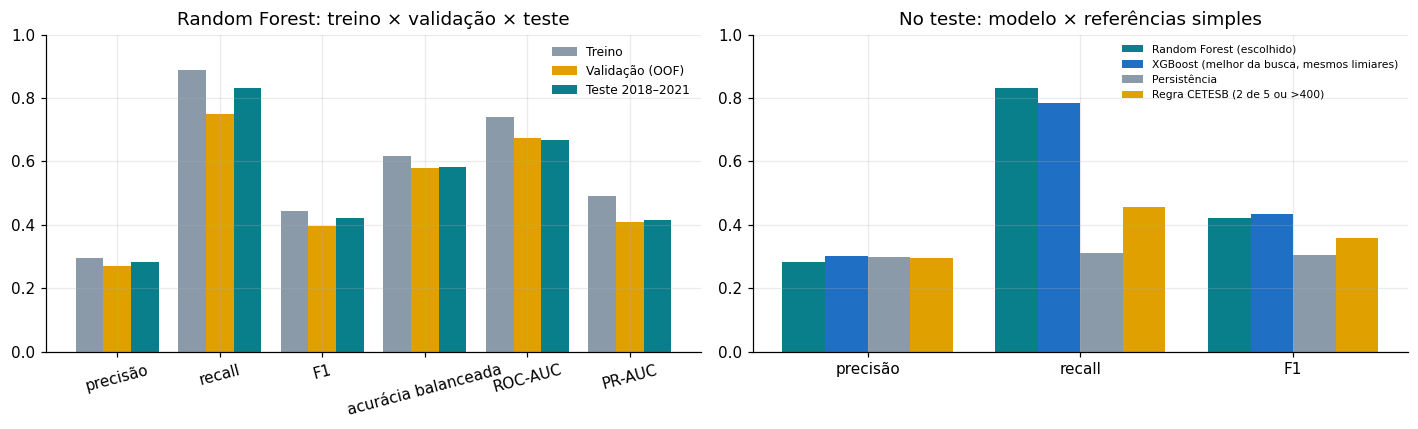

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
mets = ["precisão", "recall", "F1", "acurácia balanceada", "ROC-AUC", "PR-AUC"]
w = 0.27; xs = np.arange(len(mets))
for i, (lin, cor) in enumerate(zip(tab.index, [COR["cinza"], COR["ambar"], COR["teal"]])):
    ax[0].bar(xs + (i - 1) * w, tab.loc[lin, mets], w, label=lin, color=cor)
ax[0].set_xticks(xs, mets, rotation=15); ax[0].set_ylim(0, 1); ax[0].set_title(f"{melhor_nome}: treino × validação × teste"); ax[0].legend(frameon=False, fontsize=8)
mets2 = ["precisão", "recall", "F1"]
cores = [COR["teal"], COR["azul"], COR["cinza"], COR["ambar"]]
xs2 = np.arange(len(mets2)); w2 = 0.2
for i, (lin, cor) in enumerate(zip(comp.index, cores)):
    ax[1].bar(xs2 + (i - 1.5) * w2, comp.loc[lin, mets2], w2, label=lin, color=cor)
ax[1].set_xticks(xs2, mets2); ax[1].set_ylim(0, 1); ax[1].set_title("No teste: modelo × referências simples"); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "fig04_metricas_treino_teste.png", bbox_inches="tight"); plt.show()

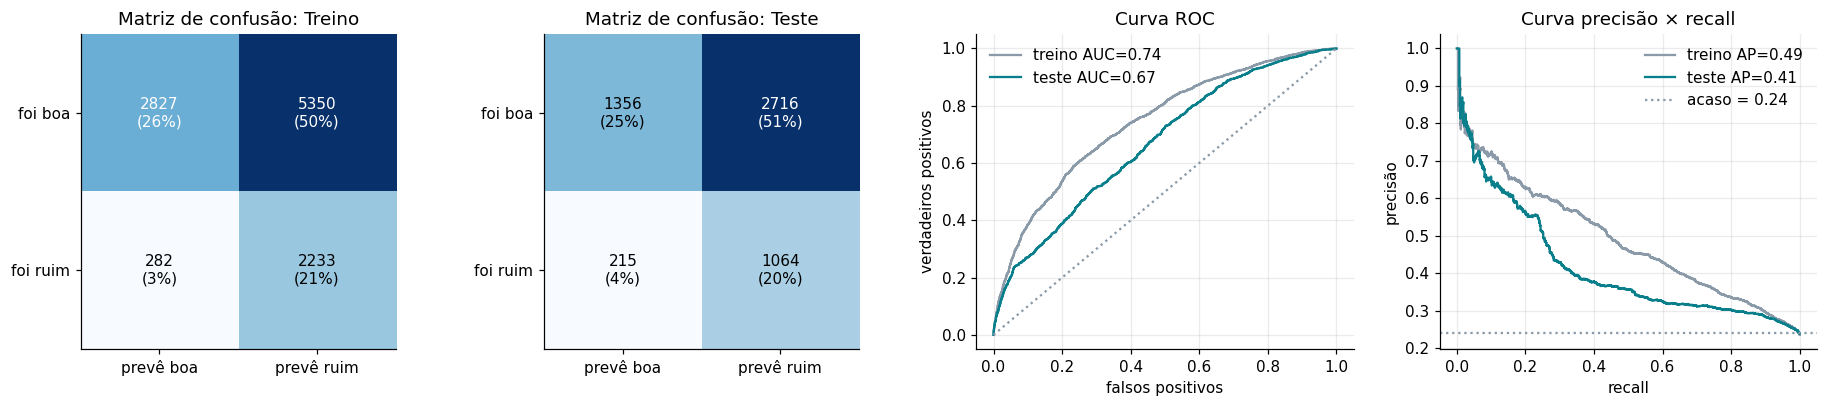

In [14]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
for a, (nome, y, pred) in zip(ax[:2], [("Treino", y_tr, alerta(p_tr, treino.municipio)), ("Teste", y_te, alerta(p_te, teste.municipio))]):
    cm = confusion_matrix(y, pred)
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, f"{v}\n({v / cm.sum():.0%})", ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    a.set_xticks([0, 1], ["prevê boa", "prevê ruim"]); a.set_yticks([0, 1], ["foi boa", "foi ruim"]); a.set_title(f"Matriz de confusão: {nome}")
for nome, y, p, cor in [("treino", y_tr, p_tr, COR["cinza"]), ("teste", y_te, p_te, COR["teal"])]:
    f, t, _ = roc_curve(y, p); ax[2].plot(f, t, color=cor, label=f"{nome} AUC={roc_auc_score(y, p):.2f}")
    pr, rc, _ = precision_recall_curve(y, p); ax[3].plot(rc, pr, color=cor, label=f"{nome} AP={average_precision_score(y, p):.2f}")
ax[2].plot([0, 1], [0, 1], ":", color=COR["cinza"]); ax[2].set_xlabel("falsos positivos"); ax[2].set_ylabel("verdadeiros positivos"); ax[2].set_title("Curva ROC"); ax[2].legend(frameon=False)
ax[3].axhline(y_te.mean(), ls=":", color=COR["cinza"], label=f"acaso = {y_te.mean():.2f}"); ax[3].set_xlabel("recall"); ax[3].set_ylabel("precisão"); ax[3].set_title("Curva precisão × recall"); ax[3].legend(frameon=False)
plt.tight_layout(); plt.savefig(FIG / "fig05_confusao_roc_pr.png", bbox_inches="tight"); plt.show()

### 5.2 Overfitting
Comparamos o desempenho no treino com o da validação e do teste:

In [15]:
gap_auc = tab.loc["Treino", "ROC-AUC"] - tab.loc["Teste 2018–2021", "ROC-AUC"]
print(f"ROC-AUC: treino {tab.loc['Treino','ROC-AUC']:.3f} · validação {tab.loc['Validação (OOF)','ROC-AUC']:.3f} · teste {tab.loc['Teste 2018–2021','ROC-AUC']:.3f} (gap treino−teste = {gap_auc:.3f})")
pior = todas.sort_values("gap PR-AUC (treino − validação)", ascending=False).iloc[0]
params_pior = {k: (int(pior[k]) if float(pior[k]).is_integer() else float(pior[k])) for k in ["max_depth", "min_samples_leaf", "n_estimators", "learning_rate"] if k in pior and pd.notna(pior[k])}
print(f"Combinação com mais overfitting: {pior.modelo} {params_pior} → PR-AUC treino {pior['PR-AUC treino']:.2f} × validação {pior['PR-AUC validação']:.2f}")

ROC-AUC: treino 0.741 · validação 0.675 · teste 0.668 (gap treino−teste = 0.073)
Combinação com mais overfitting: XGBoost {'max_depth': 6, 'n_estimators': 400, 'learning_rate': 0.1} → PR-AUC treino 1.00 × validação 0.35


**Leitura:**
- Árvores muito profundas, com `max_depth=16` e folhas de 1 exemplo, chegam perto de PR-AUC 1,0 no treino, mas **não melhoram (ou pioram) na validação**. É o caso clássico de overfitting: o modelo decora o ruído das contagens semanais de bactérias.
- A busca escolheu configurações mais rasas e com folhas maiores, que generalizam melhor.
- Ainda resta uma diferença entre treino e teste, esperada por três motivos:
  1. a coleta semanal é muito ruidosa, porque uma única chuva muda tudo;
  2. o teste inclui 2020, um período atípico, com coletas suspensas na pandemia;
  3. falta ao modelo a variável mais forte, a **chuva medida**.
- Validação e teste ficam próximos entre si, o que indica que a estimativa de desempenho é confiável.

### 5.3 O que o modelo aprendeu

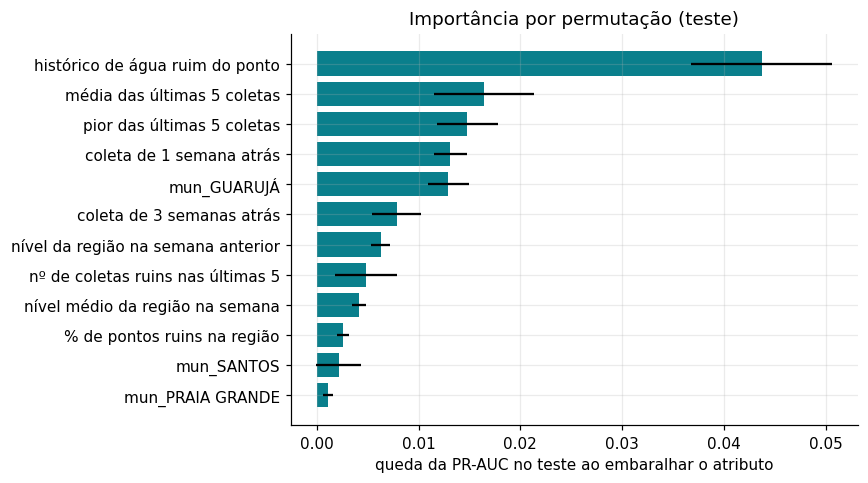

In [16]:
imp = permutation_importance(modelo, X_te, y_te, scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1)
ordem = np.argsort(imp.importances_mean)[-12:]
nomes = {"hist_ponto": "histórico de água ruim do ponto", "media5": "média das últimas 5 coletas", "max5": "pior das últimas 5 coletas",
         "acima5": "nº de coletas ruins nas últimas 5", "reg_med": "nível médio da região na semana", "reg_frac": "% de pontos ruins na região",
         "cid_frac": "% de pontos ruins no município", "reg_med_lag1": "nível da região na semana anterior", "log_lag0": "coleta atual",
         "log_lag1": "coleta de 1 semana atrás", "log_lag2": "coleta de 2 semanas atrás", "log_lag3": "coleta de 3 semanas atrás",
         "mes_sin": "época do ano (seno)", "mes_cos": "época do ano (cosseno)", "temporada": "temporada de verão", "carnaval": "semana de carnaval"}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh([nomes.get(ATRIBUTOS[i], ATRIBUTOS[i]) for i in ordem], imp.importances_mean[ordem], xerr=imp.importances_std[ordem], color=COR["teal"])
ax.set_xlabel("queda da PR-AUC no teste ao embaralhar o atributo"); ax.set_title("Importância por permutação (teste)")
plt.tight_layout(); plt.savefig(FIG / "fig06_importancia_atributos.png", bbox_inches="tight"); plt.show()

### 5.4 Foco em São Vicente (os pontos do Bandeira Viva)

,acurácia,acurácia balanceada,precisão,recall,F1,ROC-AUC,PR-AUC
São Vicente (teste),0.558,0.593,0.412,0.702,0.519,0.639,0.432
Regra CETESB em São Vicente,0.543,0.566,0.393,0.638,0.486,NaN,NaN


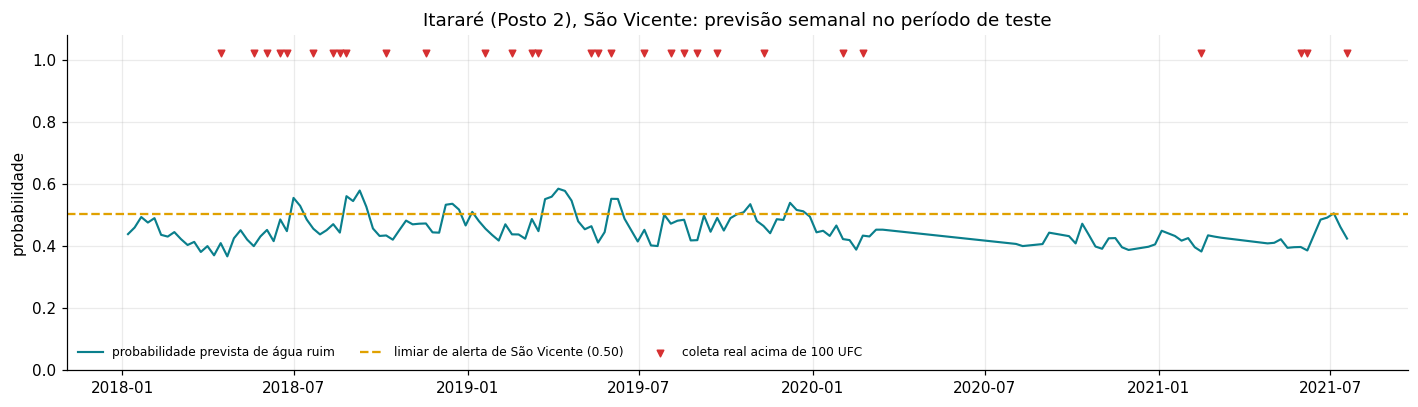

In [17]:
sv_te = teste.municipio == "SÃO VICENTE"
tab_sv = pd.DataFrame({"São Vicente (teste)": metricas(y_te[sv_te], alerta(p_te[sv_te], teste.municipio[sv_te]), p_te[sv_te]),
                       "Regra CETESB em São Vicente": metricas(y_te[sv_te], baselines["Regra CETESB (2 de 5 ou >400)"][sv_te])}).T
display(tab_sv.round(3))

itarare = teste[teste.ponto == "SÃO VICENTE | ITARARÉ (POSTO 2)"].copy()
itarare["prob"] = modelo.predict_proba(itarare[ATRIBUTOS])[:, 1]
fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(itarare.data_alvo, itarare.prob, color=COR["teal"], lw=1.4, label="probabilidade prevista de água ruim")
ax.axhline(LIMIARES["SÃO VICENTE"], ls="--", color=COR["ambar"], label=f"limiar de alerta de São Vicente ({LIMIARES['SÃO VICENTE']:.2f})")
ruim = itarare[itarare.alvo == 1]
ax.scatter(ruim.data_alvo, np.full(len(ruim), 1.02), marker="v", color=COR["coral"], s=18, label="coleta real acima de 100 UFC")
ax.set_ylim(0, 1.08); ax.set_ylabel("probabilidade"); ax.set_title("Itararé (Posto 2), São Vicente: previsão semanal no período de teste"); ax.legend(frameon=False, ncol=3, fontsize=8, loc="lower left")
plt.tight_layout(); plt.savefig(FIG / "fig07_itarare_previsao.png", bbox_inches="tight"); plt.show()

## 6. Conclusão e leitura para o cidadão

In [18]:
t = tab.loc["Teste 2018–2021"]; c = comp.loc["Regra CETESB (2 de 5 ou >400)"]
cm_te = confusion_matrix(y_te, alerta(p_te, teste.municipio)); tn, fp, fn, tp = cm_te.ravel()
resumo = {
    "pergunta": "A próxima coleta semanal do ponto vai passar de 100 UFC/100 mL de enterococos?",
    "dados": "CETESB, resultados semanais de enterococos, 37 pontos da Baixada Santista central, 2012-2021",
    "modelo_escolhido": melhor_nome, "hiperparametros": {k: (v.item() if hasattr(v, "item") else v) for k, v in melhor_grid.best_params_.items()},
    "combinacoes_testadas": {"random_forest": len(res_rf), "xgboost": len(res_xgb)},
    "limiares_por_municipio": {k: round(v, 4) for k, v in LIMIARES.items()}, "treino": tab.loc["Treino"].round(4).to_dict(), "validacao_oof": tab.loc["Validação (OOF)"].round(4).to_dict(),
    "teste": t.round(4).to_dict(), "baselines_teste": tab_base.round(4).to_dict(orient="index"), "sao_vicente_teste": tab_sv.round(4).to_dict(orient="index"),
    "confusao_teste": {"verdadeiro_negativo": int(tn), "falso_positivo": int(fp), "falso_negativo": int(fn), "verdadeiro_positivo": int(tp)},
    "exemplos": {"treino": len(treino), "teste": len(teste)},
}
def sem_nan(x):
    if isinstance(x, dict): return {k: sem_nan(v) for k, v in x.items()}
    return None if isinstance(x, float) and np.isnan(x) else x
(RES / "metricas.json").write_text(json.dumps(sem_nan(resumo), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print(f"No teste, de cada 100 semanas em que a água realmente ficou ruim, o modelo avisou antes em {t['recall']*100:.0f}.")
print(f"A regra atual de 5 semanas avisou em {c['recall']*100:.0f}.")
print(f"De cada 100 alertas do modelo, {t['precisão']*100:.0f} se confirmaram (regra atual: {c['precisão']*100:.0f}).")
print(f"Coletas ruins não avisadas no teste: {fn} de {fn + tp}.")

No teste, de cada 100 semanas em que a água realmente ficou ruim, o modelo avisou antes em 83.
A regra atual de 5 semanas avisou em 46.
De cada 100 alertas do modelo, 28 se confirmaram (regra atual: 30).
Coletas ruins não avisadas no teste: 215 de 1279.


**O que o resultado significa para quem vive e trabalha na praia:**

1. **O alerta chega uma semana antes e pega muito mais semanas ruins.** No teste (2018–2021, período que o modelo nunca viu), ele avisou com antecedência **83 de cada 100 semanas** em que a água passou do limite. A regra de cinco semanas, que define a bandeira atual, avisou **46**. Os dois acertam na mesma proporção quando dão alerta: cerca de 3 em cada 10 alertas se confirmam (28% no modelo e 30% na regra). Ou seja, o modelo encontra quase o dobro de semanas ruins sem piorar a qualidade de cada alerta.
2. **Em São Vicente o ganho é menor, mas existe.** Nos 6 pontos do Bandeira Viva, o modelo pegou 70% das semanas ruins contra 64% da regra, com precisão de 41% contra 39%. Como lá a água é ruim em mais de um terço das semanas, as duas abordagens erram menos por alerta do que na média da região.
3. **O alerta erra para o lado da prudência, e isso é uma escolha.** Cerca de 7 em cada 10 alertas não se confirmam na coleta seguinte. Num problema de saúde, um falso alarme custa um banho adiado, enquanto um aviso perdido pode custar uma gastroenterite. Por isso o app deve comunicar **risco** ("chance alta de água ruim nesta semana"), nunca certeza, e manter o boletim oficial da CETESB como fonte de verdade.
4. **O sinal mais forte é o comportamento recente do ponto e da região.** Quando vários pontos pioram juntos, quase sempre choveu e a galeria pluvial levou esgoto ao mar. Isso confirma a escolha de instalar o sensor de turbidez na galeria (disciplina de Physical Computing).
5. **Limitações honestas:**
   - a capacidade de separar semanas boas e ruins é moderada (ROC-AUC de 0,67 no teste);
   - não usamos chuva medida, porque o INMET e o CEMADEN ficaram fora do escopo deste notebook;
   - os dados terminam em jul/2021;
   - 2020 teve coletas interrompidas;
   - o modelo prevê **uma coleta por semana**, não a qualidade hora a hora.

**Próximos passos:**
- incluir a chuva acumulada de 24, 48 e 72 h do INMET (estação A765, Bertioga) e do CEMADEN, além da maré;
- atualizar a base com os boletins de 2022 em diante;
- recalibrar o limiar por ponto.